# 001 — Strain estimation on held-out recordings

Implements the protocol in `001.md`: estimate `SB01_x` from the 75 bridge acceleration channels, training on the four `_02` sweeps and testing on the four `_01` sweeps (`DIRECTION = "forward"`). Set `DIRECTION = "reverse"` to swap the two sets.

Order of the steps (as in `001.md`): recordings are assigned to train / validation / test **first**, then the channel means are computed on the fit recordings only (no PCA), then each recording is cut into windows. Windows never cross a recording boundary.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # must be set BEFORE importing keras

from pathlib import Path
import time

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import keras
from keras import layers
from numpy.lib.stride_tricks import sliding_window_view
from IPython.display import display

# --- data ---
PATH = Path("/mnt/c/Users/giuli/Documents/01_ACCADEMICO/2_PhD FIU/04 Didattica/CGN SHM/CGN project/data_100Hz.h5")
assert PATH is not None, "data_100Hz.h5 not found: put it in the data folder in the repository root"

# --- settings ---
DIRECTION = "forward"          # "forward": train on _02, test on _01 | "reverse": train on _01, test on _02
TARGET = "SB01_x"              # strain channel to predict [MPa]
FS = 100                       # sampling frequency [Hz]
WIN_S = 5                     # window length [s]
OVERLAP = 0.75                 # overlap between consecutive windows
WIN = int(WIN_S * FS)                                  # window length in samples (1000)
STRIDE = max(1, int(round(WIN * (1 - OVERLAP))))       # shift between window starts in samples (500)
CONFIGS = [{"name": "TCN, 75 channels"}]   # configurations compared on the validation folds (add more dicts to compare)
LR, BATCH, MAX_EPOCHS, PATIENCE = 1e-3, 32, 200, 20    # training settings
TCN_CHANNELS, TCN_KERNEL, TCN_DILATIONS = 16, 5, (1, 2, 4, 8, 16, 32, 64, 128)
POOL_AFTER, POOL_SIZE = (1, 3), 2     # blocks followed by a max pooling, and time steps merged by each pooling
SEED = 0
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def receptive_field(dilations, pool_after, kernel, pool_size):
    rf, jump = 1, 1
    for i, d in enumerate(dilations):
        rf += (kernel - 1) * d * jump
        if i in pool_after:
            rf += (pool_size - 1) * jump
            jump *= pool_size
    return rf

rf = receptive_field(TCN_DILATIONS, POOL_AFTER, TCN_KERNEL, POOL_SIZE)
assert rf >= WIN, f"receptive field {rf} shorter than the window {WIN}"
print("Keras", keras.__version__, "| PyTorch", torch.__version__, "| device:", DEVICE)
print(f"Window {WIN} samples, stride {STRIDE} samples, receptive field {rf}")

Keras 3.15.1 | PyTorch 2.15.0+cu132 | device: cuda
Window 500 samples, stride 125 samples, receptive field 3952


## 1 Recordings and split

Only the undamaged sweeps (`UDS`, `SM`) are used. The repeat number defines the split: `_02` / `_01`.

In [2]:
with h5py.File(PATH, "r") as f:
    all_names = list(f.keys())

rows = []
for n in all_names:
    _, position, state, mode, direction, rep = n.split("_")      # MVS_P1_UDS_SM_Y_02
    rows.append({"name": n, "position": position, "state": state, "mode": mode, "direction": direction, "rep": rep})
meta = pd.DataFrame(rows)
meta = meta[(meta["state"] == "UDS") & (meta["mode"] == "SM")].reset_index(drop=True)
meta["setting"] = meta["position"] + "/" + meta["direction"]      # P1/Y, P1/Z, P2/Y, P2/Z
assert len(meta) == 8, len(meta)

train_rep, test_rep = ("02", "01") if DIRECTION == "forward" else ("01", "02")
train_names = list(meta[meta["rep"] == train_rep].sort_values("setting")["name"])
test_names = list(meta[meta["rep"] == test_rep].sort_values("setting")["name"])
setting_of = dict(zip(meta["name"], meta["setting"]))
assert len(train_names) == 4 and len(test_names) == 4
assert [setting_of[a] for a in train_names] == [setting_of[b] for b in test_names]   # same settings in the same order
rec_names = train_names + test_names
display(meta)

,name,position,state,mode,direction,rep,setting
0,MVS_P1_UDS_SM_Y_01,P1,UDS,SM,Y,01,P1/Y
1,MVS_P1_UDS_SM_Y_02,P1,UDS,SM,Y,02,P1/Y
2,MVS_P1_UDS_SM_Z_01,P1,UDS,SM,Z,01,P1/Z
3,MVS_P1_UDS_SM_Z_02,P1,UDS,SM,Z,02,P1/Z
4,MVS_P2_UDS_SM_Y_01,P2,UDS,SM,Y,01,P2/Y
5,MVS_P2_UDS_SM_Y_02,P2,UDS,SM,Y,02,P2/Y
6,MVS_P2_UDS_SM_Z_01,P2,UDS,SM,Z,01,P2/Z
7,MVS_P2_UDS_SM_Z_02,P2,UDS,SM,Z,02,P2/Z


## 2 Loading

Only the 75 acceleration channels and the target are read, as `float32`.

In [3]:
def is_wanted(ch):
    return ch.startswith("AL") or (ch.startswith("AG") and ch.endswith(("_y", "_z"))) or ch == TARGET   # 75 accelerations + target

def load_recording(name):
    cols = {}
    with h5py.File(PATH, "r") as f:
        for group in ("acceleration", "strain"):
            for sensor in f[name][group]:
                for axis in f[name][group][sensor]:
                    ch = f"{sensor}_{axis}"
                    if is_wanted(ch):
                        cols[ch] = f[name][group][sensor][axis][:].astype("float32")
        unit = f[name]["strain"][TARGET.split("_")[0]].attrs["unit"]
    d = pd.DataFrame(cols)
    d.index = np.arange(len(d)) / FS
    d.index.name = "Time [s]"
    return d, unit

rec, units = {}, set()
for n in rec_names:
    rec[n], u = load_recording(n)
    units.add(u)

acc_cols = sorted(c for c in rec[rec_names[0]].columns if c != TARGET)
assert len(acc_cols) == 75, len(acc_cols)
for n in rec_names:
    assert set(rec[n].columns) == set(acc_cols) | {TARGET}, n
    rec[n] = rec[n][acc_cols + [TARGET]]
assert len(units) == 1
target_unit = units.pop()

for n in rec_names:
    print(f"{n}: {len(rec[n])} samples ({len(rec[n]) / FS:.2f} s)")
n_train = sum(len(rec[n]) for n in train_names)
n_test = sum(len(rec[n]) for n in test_names)
print("Train samples:", n_train, "| test samples:", n_test, "| target unit:", target_unit)
expected = (249114, 249278) if DIRECTION == "forward" else (249278, 249114)    # from 001.md
assert (n_train, n_test) == expected, f"sample counts differ from 001.md: {(n_train, n_test)} vs {expected}"

MVS_P1_UDS_SM_Y_02: 61681 samples (616.81 s)
MVS_P1_UDS_SM_Z_02: 62531 samples (625.31 s)
MVS_P2_UDS_SM_Y_02: 62520 samples (625.20 s)
MVS_P2_UDS_SM_Z_02: 62382 samples (623.82 s)
MVS_P1_UDS_SM_Y_01: 62147 samples (621.47 s)
MVS_P1_UDS_SM_Z_01: 62410 samples (624.10 s)
MVS_P2_UDS_SM_Y_01: 62386 samples (623.86 s)
MVS_P2_UDS_SM_Z_01: 62335 samples (623.35 s)
Train samples: 249114 | test samples: 249278 | target unit: MPa


## 3 Preprocessing, windows, model

- `fit_mean(names)`: the mean of each of the 75 acceleration channels, computed on the given recordings only (never on validation or test). It is subtracted from every recording; there is no scaling and no PCA.
- `make_windows(n, mean)`: one recording → windows of `WIN` samples every `STRIDE` samples. The target of a window is the strain at its last sample. The window positions depend only on the recording length, so every model sees the same target timestamps.
- `build_tcn`: causal temporal convolutional network, kept from the PCA + TCN notebook (with max pooling after blocks 1 and 3).

In [4]:
def fit_mean(names):
    X = np.concatenate([rec[n][acc_cols].values for n in names])
    return X.mean(axis=0, dtype="float64").astype("float32")

def make_windows(n, mean):
    d = rec[n]
    Z = (d[acc_cols].values - mean).astype("float32")
    y = d[TARGET].values.astype("float32")
    assert len(d) >= WIN
    X = sliding_window_view(Z, WIN, axis=0)                           # (windows, 75, WIN)
    X = np.ascontiguousarray(X.transpose(0, 2, 1)[::STRIDE])          # (windows, WIN, 75), one every STRIDE
    y_w = y[WIN - 1:][::STRIDE]                                       # target = value at the last sample
    t_end = d.index.values[WIN - 1:][::STRIDE]
    return X, y_w, t_end

def stack_windows(names, mean):
    parts = [make_windows(n, mean) for n in names]
    return tuple(np.concatenate([p[k] for p in parts]) for k in range(3))

def build_tcn(n_features):
    inputs = layers.Input(shape=(None, n_features))
    x = layers.Conv1D(TCN_CHANNELS, 1, padding="causal")(inputs)
    for i, dil in enumerate(TCN_DILATIONS):
        res = x
        x = layers.Conv1D(TCN_CHANNELS, TCN_KERNEL, padding="causal", dilation_rate=dil)(x)
        x = layers.Activation("relu")(layers.Add()([res, x]))
        if i in POOL_AFTER:                                           # pooling after the sum and the ReLU
            x = layers.MaxPooling1D(pool_size=POOL_SIZE, padding="same")(x)
    out = layers.Dense(1)(x[:, -1, :])
    model = keras.Model(inputs, out)
    model.compile(optimizer=keras.optimizers.Adam(LR), loss="mse")
    return model

def train_tcn(X, y, X_val=None, y_val=None, epochs=MAX_EPOCHS):
    """With validation data: early stopping, restores the best weights. Without: exactly `epochs` epochs."""
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    with keras.device(DEVICE):
        model = build_tcn(X.shape[2])
        if X_val is not None:
            es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True)
            h = model.fit(X, y, validation_data=(X_val, y_val), epochs=epochs, batch_size=BATCH, verbose=0, callbacks=[es])
            best = int(np.argmin(h.history["val_loss"])) + 1
        else:
            h = model.fit(X, y, epochs=epochs, batch_size=BATCH, verbose=0)
            best = epochs
    return model, best, h.history

def predict(model, X):
    with keras.device(DEVICE):
        return model.predict(X, batch_size=256, verbose=0).ravel()

def rmse(t, p): return float(np.sqrt(np.mean((t - p) ** 2)))
def r2(t, p): return float(1 - np.sum((t - p) ** 2) / np.sum((t - t.mean()) ** 2))

## 4 Validation folds (training recordings only)

Four folds. Each fold holds out one whole training recording (one shaker setting) for validation; the channel means and the network are fitted on the other three. The test recordings are not touched here.

In [5]:
cv_rows = []
cv_hist = {}
for ci, cfg in enumerate(CONFIGS):
    for k, val_name in enumerate(train_names):
        fit_names = [n for n in train_names if n != val_name]
        mean_k = fit_mean(fit_names)
        X_fit, y_fit, _ = stack_windows(fit_names, mean_k)
        X_val, y_val, _ = make_windows(val_name, mean_k)
        t0 = time.perf_counter()
        model, best, h = train_tcn(X_fit, y_fit, X_val, y_val)
        cv_hist[(ci, k)] = h
        p = predict(model, X_val)
        cv_rows.append({"config": ci, "name": cfg["name"], "fold": k + 1, "validation": val_name,
                        "fit windows": len(X_fit), "val windows": len(X_val), "best epoch": best,
                        "val RMSE": rmse(y_val, p), "val R2": r2(y_val, p),
                        "baseline RMSE": rmse(y_val, np.full_like(y_val, y_fit.mean())),
                        "seconds": time.perf_counter() - t0})
        print(cv_rows[-1])

cv = pd.DataFrame(cv_rows)
display(cv.round(4))
summary = cv.groupby("config")[["val RMSE", "val R2", "best epoch"]].mean()
display(summary.round(4))
best_config = int(summary["val RMSE"].idxmin())
final_epochs = int(round(cv[cv["config"] == best_config]["best epoch"].median()))
print(f"Selected config {best_config}: {CONFIGS[best_config]} | epochs for the final fit: {final_epochs}")

{'config': 0, 'name': 'TCN, 75 channels', 'fold': 1, 'validation': 'MVS_P1_UDS_SM_Y_02', 'fit windows': 1490, 'val windows': 490, 'best epoch': 4, 'val RMSE': 0.07331829518079758, 'val R2': -0.5792715549468994, 'baseline RMSE': 0.058494940400123596, 'seconds': 84.70475575899763}
{'config': 0, 'name': 'TCN, 75 channels', 'fold': 2, 'validation': 'MVS_P1_UDS_SM_Z_02', 'fit windows': 1483, 'val windows': 497, 'best epoch': 17, 'val RMSE': 0.0727899819612503, 'val R2': -0.25924837589263916, 'baseline RMSE': 0.06487175822257996, 'seconds': 134.96583207300137}
{'config': 0, 'name': 'TCN, 75 channels', 'fold': 3, 'validation': 'MVS_P2_UDS_SM_Y_02', 'fit windows': 1483, 'val windows': 497, 'best epoch': 3, 'val RMSE': 0.06660623103380203, 'val R2': -0.12881600856781006, 'baseline RMSE': 0.06272821873426437, 'seconds': 86.62304965200019}
{'config': 0, 'name': 'TCN, 75 channels', 'fold': 4, 'validation': 'MVS_P2_UDS_SM_Z_02', 'fit windows': 1484, 'val windows': 496, 'best epoch': 23, 'val RMSE':

,config,name,fold,validation,fit windows,val windows,best epoch,val RMSE,val R2,baseline RMSE,seconds
0,0,"TCN, 75 channels",1,MVS_P1_UDS_SM_Y_02,1490,490,4,0.0733,-0.5793,0.0585,84.7048
1,0,"TCN, 75 channels",2,MVS_P1_UDS_SM_Z_02,1483,497,17,0.0728,-0.2592,0.0649,134.9658
2,0,"TCN, 75 channels",3,MVS_P2_UDS_SM_Y_02,1483,497,3,0.0666,-0.1288,0.0627,86.6230
3,0,"TCN, 75 channels",4,MVS_P2_UDS_SM_Z_02,1484,496,23,0.0762,0.0303,0.0775,159.4009


,val RMSE,val R2,best epoch
config,,,
0,0.0722,-0.2342,11.75


Selected config 0: {'name': 'TCN, 75 channels'} | epochs for the final fit: 10


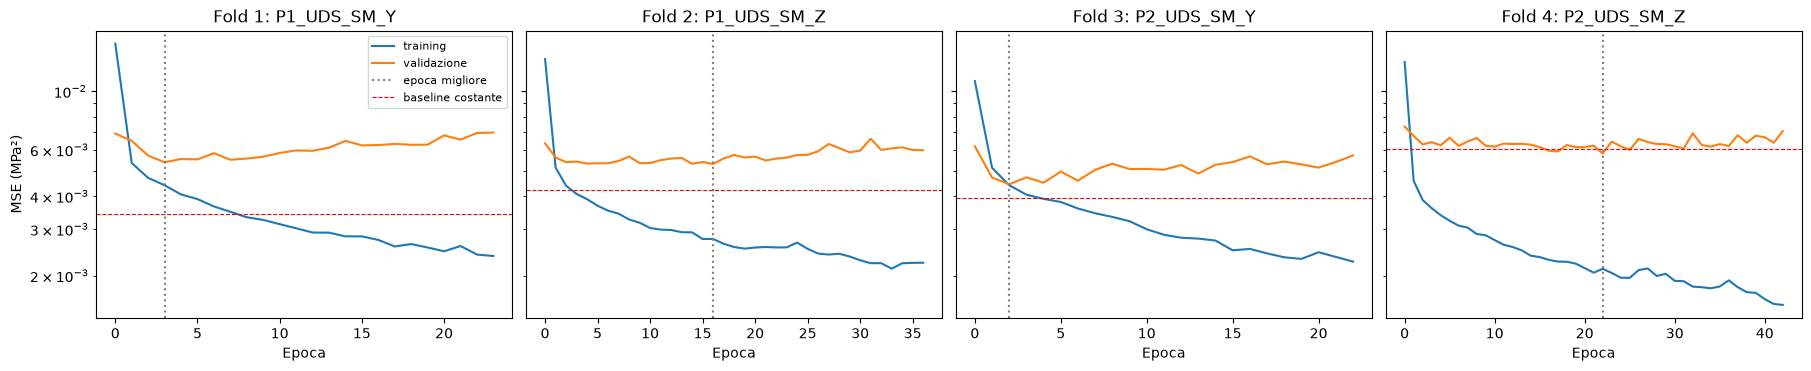

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), constrained_layout=True, sharey=True)
for k, ax in enumerate(axes):
    h = cv_hist[(best_config, k)]
    row = cv[(cv["config"] == best_config) & (cv["fold"] == k + 1)].iloc[0]
    ax.plot(h["loss"], label="training")
    ax.plot(h["val_loss"], label="validazione")
    ax.axvline(row["best epoch"] - 1, color="gray", ls=":", label="epoca migliore")
    ax.axhline(row["baseline RMSE"] ** 2, color="red", ls="--", lw=0.8, label="baseline costante")
    ax.set(title=f"Fold {k + 1}: {row['validation'][4:-3]}", xlabel="Epoca", yscale="log")
axes[0].set_ylabel("MSE (MPa²)")
axes[0].legend(fontsize=8)
plt.show()

## 5 Final fit on all four training recordings and test

The selected configuration is refitted on the four training recordings (channel means included), with the number of epochs found in the validation folds. No validation set remains for early stopping. Then it is scored on each test recording.
Baseline: constant prediction equal to the mean of the training window targets.

In [7]:
cfg = CONFIGS[best_config]
mean_f = fit_mean(train_names)
X_tr, y_tr, _ = stack_windows(train_names, mean_f)
model_f, _, hist = train_tcn(X_tr, y_tr, epochs=final_epochs)
print(f"Train windows: {len(X_tr)} | final training loss: {hist['loss'][-1]:.5f}")

rows, test_pred = [], {}
for n_te, n_tr in zip(test_names, train_names):
    X_te, y_te, t_te = make_windows(n_te, mean_f)
    p = predict(model_f, X_te)
    base = np.full_like(y_te, y_tr.mean())
    test_pred[n_te] = (t_te, y_te, p)
    rows.append({"setting": setting_of[n_te], "test recording": n_te, "windows": len(y_te),
                 "RMSE model": rmse(y_te, p), "R2 model": r2(y_te, p),
                 "RMSE baseline": rmse(y_te, base), "R2 baseline": r2(y_te, base)})
res = pd.DataFrame(rows)
mean_row = {"setting": "mean", "test recording": "", "windows": int(res["windows"].sum())}
for c in ("RMSE model", "R2 model", "RMSE baseline", "R2 baseline"):
    mean_row[c] = res[c].mean()                         # equally weighted mean of the four recordings
res = pd.concat([res, pd.DataFrame([mean_row])], ignore_index=True)
print(f"Direction: {DIRECTION} | RMSE in {target_unit}")
display(res.round(4))

Train windows: 1980 | final training loss: 0.00313
Direction: forward | RMSE in MPa


,setting,test recording,windows,RMSE model,R2 model,RMSE baseline,R2 baseline
0,P1/Y,MVS_P1_UDS_SM_Y_01,494,0.1535,-0.0184,0.1521,-0.0001
1,P1/Z,MVS_P1_UDS_SM_Z_01,496,0.1442,0.0657,0.1491,-0.0000
2,P2/Y,MVS_P2_UDS_SM_Y_01,496,0.1945,0.0062,0.1951,-0.0001
3,P2/Z,MVS_P2_UDS_SM_Z_01,495,0.1891,-0.0694,0.1828,-0.0000
4,mean,,1981,0.1703,-0.0040,0.1698,-0.0001


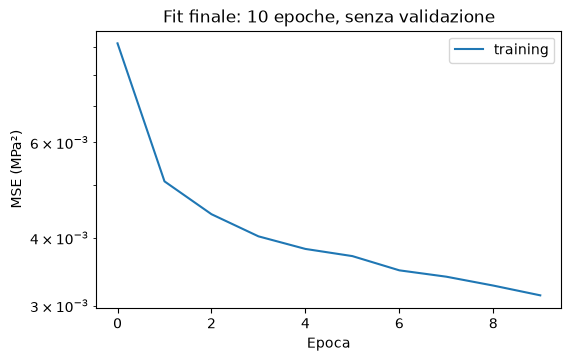

In [8]:
plt.figure(figsize=(6, 3.6))
plt.plot(hist["loss"], label="training")
plt.xlabel("Epoca"); plt.ylabel("MSE (MPa²)"); plt.yscale("log")
plt.title(f"Fit finale: {final_epochs} epoche, senza validazione")
plt.legend(); plt.show()


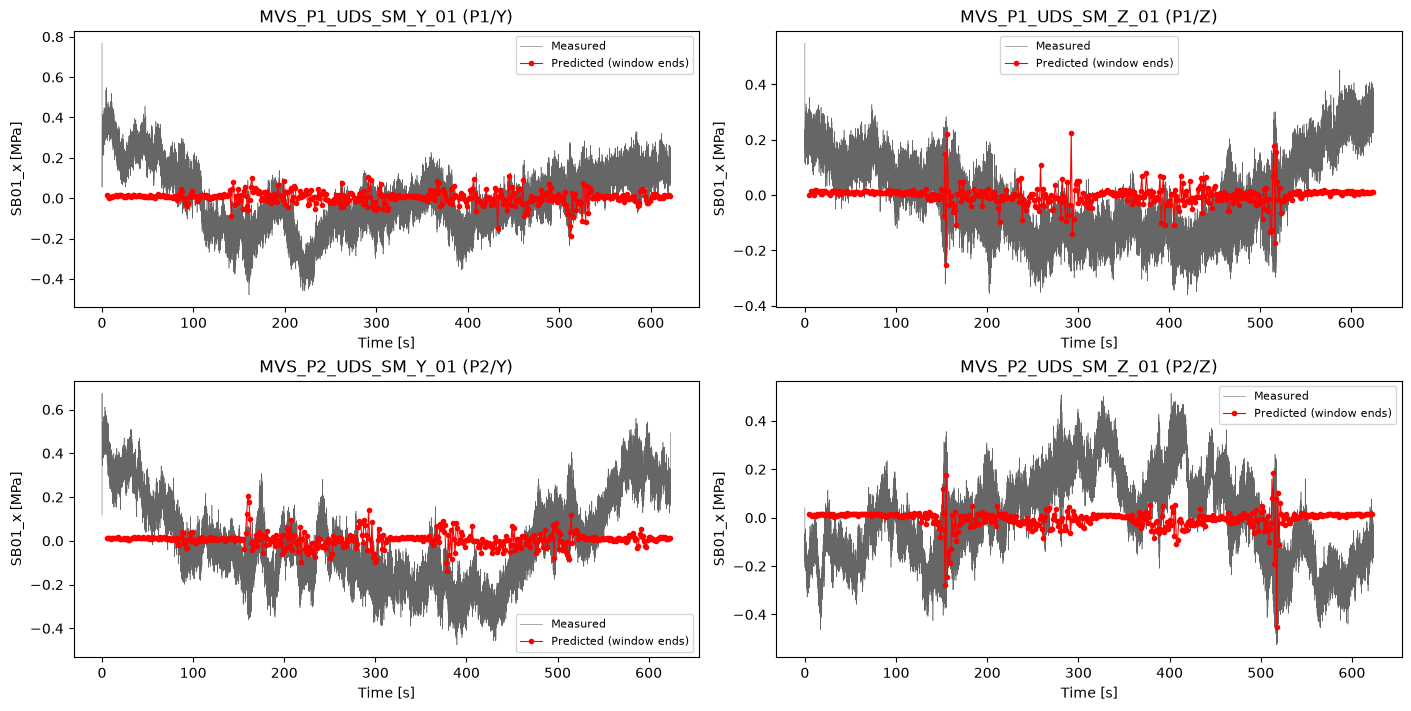

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), constrained_layout=True)
for ax, n in zip(axes.ravel(), test_names):
    t, y, p = test_pred[n]
    ax.plot(rec[n].index, rec[n][TARGET], color="black", lw=0.4, alpha=0.6, label="Measured")
    ax.plot(t, p, "o-", color="red", ms=3, lw=0.8, label="Predicted (window ends)")
    ax.set(title=f"{n} ({setting_of[n]})", xlabel="Time [s]", ylabel=f"{TARGET} [{target_unit}]")
    ax.legend(fontsize=8)
plt.show()